# FDTD photonic circuits: waveguide modes, couplers and ring resonators

Integrated photonics guides light in waveguides a fraction of a micrometre
wide and builds circuits from a few elements: straight and bent waveguides,
**directional couplers** that split light between two waveguides, and
**ring resonators** that filter it or sense what surrounds them. This
notebook builds and validates these elements with the FDTD of
`pyoptics.fdtd` (continuing notebooks [57](57_fdtd_basics.ipynb) and
[59](59_fdtd_metals_plasmons.ipynb)):

1. waveguide modes from a finite-difference mode solver, against the
   analytic slab waveguide,
2. launching a single mode: the mode source, mode monitors and
   S-parameters,
3. bends: radiation loss against the bend radius,
4. a directional coupler: supermodes, coupled-mode theory and the FDTD,
5. an add-drop ring resonator: spectrum, free spectral range and Q (matrix
   pencil),
6. ring resonator sensing: the resonance shift with the refractive index of
   the surroundings.

**The 2D model.** The simulations are a top view of a planar circuit:
the waveguides are invariant along z (out of the plane), which in the
real chip is the thickness of a thin silicon layer. The effective index
method folds that thickness into an index: a 220 nm silicon slab guides
light at 1.55 µm with an effective index of about 2.85 for E in the plane
of the slab, and that is the core index used here. E in the chip plane is
the **Hz** polarization of the 2D model (fields Ex, Ey, Hz); it is the
"TE" mode of silicon photonics. The cladding is silica (n = 1.44) or water
(n = 1.33).

Lengths are in µm, times in µm/c.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)

CORE = fdtd.Medium.from_index(2.85)     # effective index of a 220 nm Si slab
OXIDE = fdtd.Medium.from_index(1.44)
WATER = fdtd.Medium.from_index(1.33)
WL = 1.55
H = 0.02                                # cell size: 27 cells per wavelength in the core
t_start = time.perf_counter()

numba kernels available: True


## 1. Waveguide modes

A waveguide along x with a cross section $\varepsilon(y)$ guides modes
$\psi(y)\,e^{i(\beta x - \omega t)}$ with the effective index
$n_\mathrm{eff} = \beta/k_0$. For the Hz polarization the wave equation
for Hz across the waveguide is

$$\varepsilon\,\frac{d}{dy}\left(\frac{1}{\varepsilon}\frac{dH_z}{dy}\right) + k_0^2\,\varepsilon\,H_z = \beta^2 H_z ,$$

(for Ez simply $E_z'' + k_0^2\varepsilon E_z = \beta^2 E_z$). The mode
solver `fdtd.waveguide_modes()` discretizes it with the three-point
differences of the Yee grid, which makes it a symmetric tridiagonal
eigenvalue problem, solved in O(n) per mode. Each mode comes back with its
transverse E and H, normalized to unit power.

For a symmetric slab of width $d$ the modes are known exactly
($\kappa = k_0\sqrt{n_1^2 - n_\mathrm{eff}^2}$,
$\gamma = k_0\sqrt{n_\mathrm{eff}^2 - n_2^2}$):

$$\kappa\,\frac{d}{2} = m\,\frac{\pi}{2} + \arctan\!\left(r\,\frac{\gamma}{\kappa}\right),\qquad r = 1\ (E_z),\quad r = \frac{n_1^2}{n_2^2}\ (H_z),$$

with $m = 0, 1, \dots$ the mode order. The factor $n_1^2/n_2^2$ comes from
the continuity of $H_z$ and of $E_x \propto (1/\varepsilon)\,\partial H_z/\partial y$
at the walls: the Hz polarization sees the index step through the
discontinuous normal E, and it is the reason why it needs anisotropic
sub-cell averaging in the FDTD.

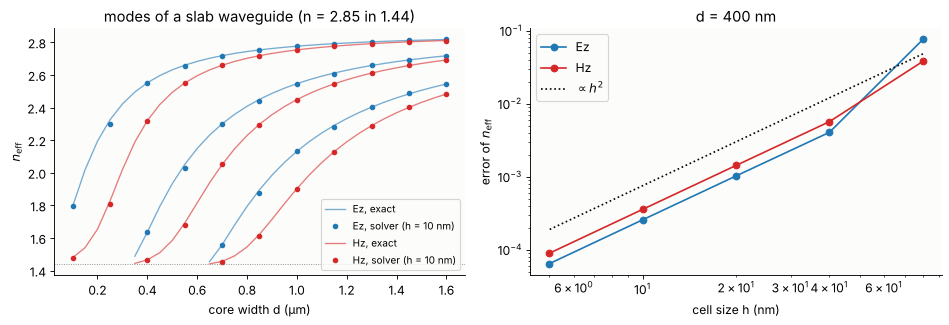

In [2]:
def slab_neff(n1, n2, d, wl, mode, m=0):
    # exact effective index of mode m of a symmetric slab (nan if cut off)
    k0 = 2*np.pi/wl
    r = (n1/n2)**2 if mode == "Hz" else 1.0
    f = lambda ne: k0*np.sqrt(n1**2 - ne**2)*d/2 - m*np.pi/2 - \
        np.arctan(r*np.sqrt(ne**2 - n2**2)/np.sqrt(n1**2 - ne**2))
    lo, hi = n2 + 1e-12, n1 - 1e-12
    return brentq(f, lo, hi) if f(lo) > 0 else np.nan


def slab_eps(width, h, n1=2.85, n2=1.44, half=2.0):
    # cross section with the walls on cell faces; eps_long sits on the faces
    y = (np.arange(-int(half/h), int(half/h)) + 0.5)*h
    eps = np.where(np.abs(y) < width/2, n1**2, n2**2)
    yl = np.concatenate([y - h/2, [y[-1] + h/2]])
    el = np.where(np.isclose(np.abs(yl), width/2), (n1**2 + n2**2)/2,
                  np.where(np.abs(yl) < width/2, n1**2, n2**2))
    return y, eps, el


widths = np.linspace(0.1, 1.6, 31)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for mode, color in (("Ez", "C0"), ("Hz", "C3")):
    for m in range(3):
        exact = [slab_neff(2.85, 1.44, w, WL, mode, m) for w in widths]
        ax[0].plot(widths, exact, color=color, lw=1.2, alpha=0.6,
                   label="%s, exact" % mode if m == 0 else None)
        solved = []
        for w in widths[::3]:
            y, eps, el = slab_eps(w, 0.01)
            ms = fdtd.waveguide_modes(eps, 0.01, WL, mode, num_modes=3,
                                      eps_long=el if mode == "Hz" else None)
            solved.append(ms[m].n_eff if len(ms) > m else np.nan)
        ax[0].plot(widths[::3], solved, "o", color=color, ms=4,
                   label="%s, solver (h = 10 nm)" % mode if m == 0 else None)
ax[0].axhline(1.44, color="0.5", lw=0.8, ls=":")
ax[0].set(xlabel="core width d (µm)", ylabel=r"$n_\mathrm{eff}$",
          title="modes of a slab waveguide (n = 2.85 in 1.44)")
ax[0].legend(fontsize=9)

# convergence of the fundamental mode with the cell size
hs = 0.4/np.array([5, 10, 20, 40, 80])
for mode, color in (("Ez", "C0"), ("Hz", "C3")):
    ref = slab_neff(2.85, 1.44, 0.4, WL, mode)
    err = []
    for h in hs:
        y, eps, el = slab_eps(0.4, h)
        err.append(abs(fdtd.waveguide_modes(eps, h, WL, mode,
                                            eps_long=el if mode == "Hz" else None)[0].n_eff - ref))
    ax[1].loglog(hs*1e3, err, "o-", color=color, label=mode)
ax[1].loglog(hs*1e3, 3e-3*(hs/0.02)**2, "k:", label=r"$\propto h^2$")
ax[1].set(xlabel="cell size h (nm)", ylabel=r"error of $n_\mathrm{eff}$", title="d = 400 nm")
ax[1].legend()
plt.tight_layout()

The solver reproduces the exact dispersion of all modes and converges
with the square of the cell size. The Hz modes have lower effective
indices than the Ez modes: their field reaches further into the cladding,
which makes them more sensitive to it (useful for sensing, section 6) but
also less tightly bound in bends. The waveguides are single-mode below a
width of $\lambda/(2\,\mathrm{NA}) = 310$ nm; the 400 nm wide waveguides
used below have a second mode just above its cutoff, with most of its field
in the cladding. The mode source launches only the fundamental mode, and
bends strip off the second one.

The mode profiles show the discontinuity of the normal field $E_y$ at the
core walls (by $\varepsilon_\mathrm{core}/\varepsilon_\mathrm{clad} = 3.9$),
while Hz is smooth:

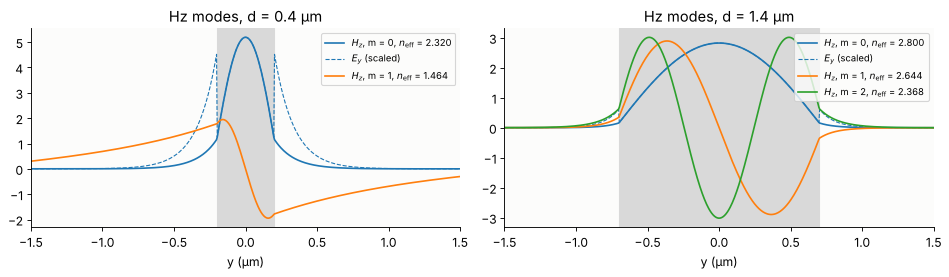

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, w in enumerate((0.4, 1.4)):
    y, eps, el = slab_eps(w, 0.005)
    for m in fdtd.waveguide_modes(eps, 0.005, WL, "Hz", num_modes=3, eps_long=el):
        line, = ax[k].plot(y, m.H, label=r"$H_z$, m = %d, $n_\mathrm{eff}$ = %.3f" % (m.order, m.n_eff))
        if m.order == 0:
            ax[k].plot(y, m.E/np.abs(m.E).max()*np.abs(m.H).max(), "--", color=line.get_color(),
                       lw=1, label=r"$E_y$ (scaled)")
    ax[k].axvspan(-w/2, w/2, color="0.85", zorder=0)
    ax[k].set(xlim=(-1.5, 1.5), xlabel="y (µm)", title="Hz modes, d = %g µm" % w)
    ax[k].legend(fontsize=8.5, loc="upper right")
plt.tight_layout()

## 2. Launching a mode: mode source, mode monitors, S-parameters

A point or line source excites every mode of a waveguide and radiates into
the cladding as well, in both directions. For circuits we want one mode
travelling one way, with known power. `fdtd.ModeSource` does this with the
total-field / scattered-field method on a line across the waveguide: the
incident field is the mode profile times a 1D wave from an auxiliary grid
filled with $\varepsilon = n_\mathrm{eff}^2$. Ahead of the line the
simulation holds the total field, behind it only what the structure sends
back.

For this to be clean, the mode must be an exact solution of the
*discretized* equations. On the Yee grid the second derivatives become
$k_0^2 \to \tilde k_0^2 = \left(\tfrac{2}{\Delta t}\sin\tfrac{\omega\Delta t}{2}\right)^2$
and $\beta^2 \to \tilde\beta^2 = \left(\tfrac{2}{\Delta x}\sin\tfrac{\beta\Delta x}{2}\right)^2$;
`fdtd.find_modes()` solves the cross section of a simulation, rasterized
with its sub-cell averaging, with these replacements. The mode then
travels down a straight waveguide without changing its shape, and the
auxiliary 1D grid has exactly the same phase velocity at the centre
wavelength.

`fdtd.ModeMonitor` takes the Fourier transform of $E_y$ and $H_z$ on a line
and projects it on the forward and backward mode at each wavelength:

$$a_\pm = \tfrac14\int\left(\mathbf E \times \mathbf H_m^* \pm \mathbf E_m^* \times \mathbf H\right)\cdot\hat x\,dy ,$$

so that $|a_\pm|^2$ is the power in each direction. Ratios of amplitudes
at two monitors are S-parameters (`fdtd.s_parameters`).

A straight waveguide is the test: a pulse from the mode source, monitors
behind the source, just after it and 4 µm downstream.

Mode(Hz, order=0, wavelength=1.55, n_eff=2.324085)
transmission |S21|^2 - 1:  max 1.2e-04
phase of S21 - beta*L:     max 1.3e-04 rad
backward power behind the source: max 1.7e-04 of the forward power


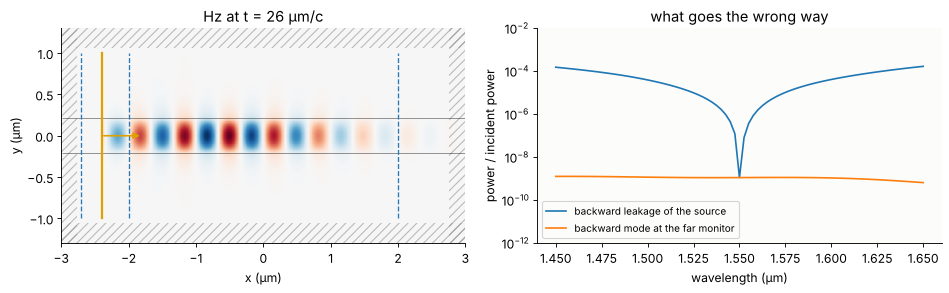

In [4]:
w = 0.4
wls = np.linspace(1.45, 1.65, 81)
pulse = fdtd.GaussianPulse(WL, bandwidth=0.06)
ext = (-1.0, 1.0)
src = fdtd.ModeSource(-2.4, pulse, extent=ext)
back = fdtd.ModeMonitor(-2.7, wls, extent=ext)
m1 = fdtd.ModeMonitor(-2.0, wls, extent=ext)
m2 = fdtd.ModeMonitor(2.0, wls, extent=ext)
snap = fdtd.Snapshots("Hz", every=20)
straight = fdtd.Simulation(fdtd.Grid((6.0, 2.6), H), [(fdtd.Rect((0, 0), (10, w)), CORE)],
                           [src], [back, m1, m2, snap], mode="Hz", background=OXIDE)
straight.run(time=70)
print(src.mode)

a1, a2 = m1.amplitudes()[0], m2.amplitudes()[0]
P_in = np.abs(a1)**2
beta = np.array([m.beta for m in m1.modes])
print("transmission |S21|^2 - 1:  max %.1e" % np.max(np.abs(np.abs(a2/a1)**2 - 1)))
print("phase of S21 - beta*L:     max %.1e rad" % np.max(np.abs(np.angle(a2/a1*np.exp(-1j*beta*4.0)))))
print("backward power behind the source: max %.1e of the forward power"
      % np.max(np.abs(back.amplitudes()[1])**2/P_in))

fig = plt.figure(figsize=(12, 3.8))
ax = fig.add_subplot(1, 2, 1)
stack = snap.stack()
k = np.argmax([np.abs(f).max() for f in stack.frames][:len(stack)//2 + 6]) + 4
x, y = stack.coords
ax.imshow(stack.frames[k].astype(float).T, origin="lower", extent=fplot._extent((x, y)),
          cmap="RdBu_r", aspect="auto")
fplot._structure_outline(ax, straight)
fplot._overlays(ax, straight)
ax.set(xlabel="x (µm)", ylabel="y (µm)", title="Hz at t = %.0f µm/c" % stack.times[k])
ax = fig.add_subplot(1, 2, 2)
ax.semilogy(wls, np.abs(back.amplitudes()[1])**2/P_in, label="backward leakage of the source")
ax.semilogy(wls, np.abs(m2.amplitudes()[1])**2/P_in, label="backward mode at the far monitor")
ax.set(xlabel="wavelength (µm)", ylabel="power / incident power", ylim=(1e-12, 1e-2),
       title="what goes the wrong way")
ax.legend(fontsize=9)
plt.tight_layout()

The transmission of the straight waveguide is 1 to within 1e-4, and its
phase is $\beta L$ with the β of the mode solver to 1e-4 rad: the mode is
an eigenmode of the grid. At the centre wavelength, where the 1D wave of
the source has exactly the mode's phase velocity, nothing leaks backwards;
away from it the dispersion of the mode differs a little from that of the
uniform 1D medium and a fraction leaks, up to 2e-4 at the edges of this
band. That is the noise floor of reflection measurements.

## 3. Bends

A bent waveguide radiates: on the outside of the bend the phase fronts
would have to travel faster than light in the cladding, and beyond the
radius where they would, the field tears off and radiates. The loss grows
exponentially as the radius shrinks, and faster for weakly guiding
waveguides. With the mode monitors, the transmission of a 90° bend into
the mode of the output waveguide comes straight out. `fdtd.Bend` draws the
quarter circle.

loss at 1.55 µm (dB): {0.5: 2.988, 0.75: 1.869, 1.0: 1.032, 1.5: 0.283, 2.0: 0.142, 3.0: 0.053}


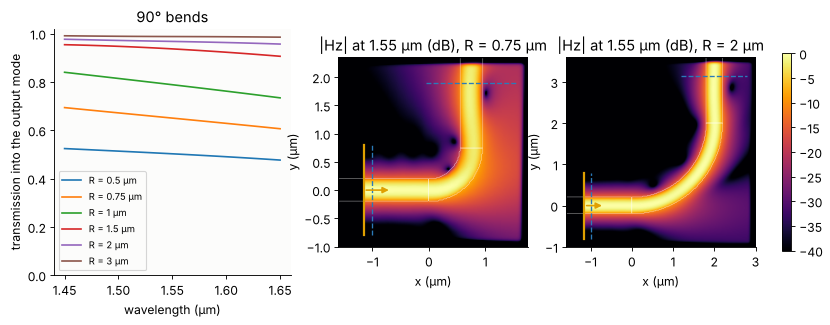

In [5]:
def bend_sim(R, monitors_every=8):
    st = [(fdtd.Rect((-5, 0), (10, w)), CORE),
          (fdtd.Bend((0, R), R, w, (-np.pi/2, 0)), CORE),
          (fdtd.Rect((R, R + 5), (w, 10)), CORE)]
    x0, x1, y0, y1 = -1.6, R + 1.0, -1.0, R + 1.6
    grid = fdtd.Grid((x1 - x0, y1 - y0), H, center=((x0 + x1)/2, (y0 + y1)/2))
    inc = fdtd.ModeMonitor(x0 + 0.6, wls, extent=(-0.8, 0.8), every=monitors_every)
    out = fdtd.ModeMonitor(y1 - 0.45, wls, axis=1, extent=(R - 0.8, R + 0.8),
                           every=monitors_every)
    dft = fdtd.DFTField([WL], components=["Hz"])
    sim = fdtd.Simulation(grid, st, [fdtd.ModeSource(x0 + 0.45, pulse, extent=(-0.8, 0.8))],
                          [inc, out, dft], mode="Hz", background=OXIDE)
    sim.run(time=100)
    return sim, inc.power()[0], out.power()[0], dft


radii = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
T_bend = {}
for R in radii:
    sim, Pin, Pout, dft = bend_sim(R)
    T_bend[R] = Pout/Pin
    ax[0].plot(wls, T_bend[R], label="R = %g µm" % R)
    if R in (0.75, 2.0):
        a = ax[1] if R == 0.75 else ax[2]
        x, y = dft.coords("Hz")
        F = dft.field("Hz")[0]
        im = a.imshow(20*np.log10(np.abs(F.T)/np.abs(F).max() + 1e-6), origin="lower",
                      extent=fplot._extent((x, y)), cmap="inferno", vmin=-40, vmax=0)
        fplot._structure_outline(a, sim, color="w", lw=0.5)
        fplot._overlays(a, sim, show_pml=False)
        a.set(xlabel="x (µm)", ylabel="y (µm)", title="|Hz| at 1.55 µm (dB), R = %g µm" % R)
ax[0].set(xlabel="wavelength (µm)", ylabel="transmission into the output mode",
          title="90° bends", ylim=(0, 1.02))
ax[0].legend(fontsize=8.5)
plt.colorbar(im, ax=ax[1:], shrink=0.8)
print("loss at 1.55 µm (dB):", {R: round(float(-10*np.log10(T_bend[R][40])), 3) for R in radii})

At R = 0.5 µm half of the light is lost, at 3 µm about 1 %; the
radiation leaves tangentially from the outside of the bend (left map).
Longer wavelengths are bound less tightly and lose more. Real silicon
bends get away with smaller radii because the true lateral contrast (Si to
oxide, 3.48 to 1.44 in the core layer) is larger than this effective-index
model's.

## 4. Directional coupler

Two waveguides close to each other exchange power through their
evanescent fields. Together they form one waveguide with two modes, an
**even** and an **odd supermode**, with different effective indices
$n_e > n_o$. Light launched into one waveguide is their sum; along x the
two run out of phase, and after the **coupling length**

$$L_c = \frac{\lambda}{2\,(n_e - n_o)}$$

the light has moved to the other waveguide. `fdtd.section_modes()` solves a
cross section drawn with shapes (on the same grid as the FDTD), here the
two waveguides at a range of gaps:

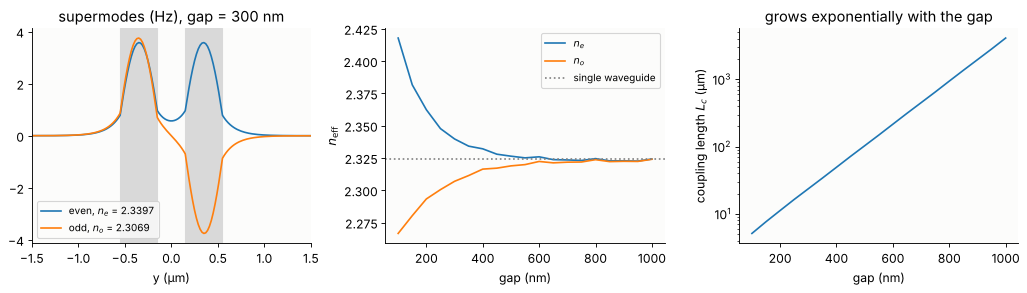

In [6]:
def pair(gap):
    yc = (w + gap)/2
    return [(fdtd.Rect((0, -yc), (1, w)), CORE), (fdtd.Rect((0, yc), (1, w)), CORE)]


gaps = np.linspace(0.1, 1.0, 19)
sup = [fdtd.section_modes(pair(g), WL, (-2.5, 2.5), H, "Hz", OXIDE, num_modes=2) for g in gaps]
ne = np.array([s[0].n_eff for s in sup])
no = np.array([s[1].n_eff for s in sup])
Lc = WL/(2*(ne - no))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
s = sup[4]
ax[0].plot(s[0].coords, s[0].H, label="even, $n_e$ = %.4f" % s[0].n_eff)
ax[0].plot(s[1].coords, s[1].H, label="odd, $n_o$ = %.4f" % s[1].n_eff)
for c in (-1, 1):
    ax[0].axvspan(c*(w + gaps[4])/2 - w/2, c*(w + gaps[4])/2 + w/2, color="0.85", zorder=0)
ax[0].set(xlim=(-1.5, 1.5), xlabel="y (µm)", title="supermodes (Hz), gap = %.0f nm" % (gaps[4]*1e3))
ax[0].legend(fontsize=9)
ax[1].plot(gaps*1e3, ne, label="$n_e$")
ax[1].plot(gaps*1e3, no, label="$n_o$")
ax[1].axhline(fdtd.section_modes([(fdtd.Rect((0, 0), (1, w)), CORE)], WL, (-2, 2), H, "Hz",
                                OXIDE)[0].n_eff,
              color="0.5", ls=":", label="single waveguide")
ax[1].set(xlabel="gap (nm)", ylabel=r"$n_\mathrm{eff}$")
ax[1].legend(fontsize=9)
ax[2].semilogy(gaps*1e3, Lc)
ax[2].set(xlabel="gap (nm)", ylabel="coupling length $L_c$ (µm)", title="grows exponentially with the gap")
plt.tight_layout()

A real coupler brings the waveguides together and apart with S-bends
(`fdtd.SBend`, `fdtd.Path`), which couple as well. Coupled-mode theory
handles that with a local coupling constant $\kappa(g) = \pi(n_e - n_o)/\lambda$
at the local gap $g(x)$: the power that crosses over is

$$P_\mathrm{cross} = \sin^2\!\int \kappa(g(x))\,dx ,$$

with $\kappa(g)$ interpolated from the supermodes above. The FDTD of the
whole coupler (200 nm gap, 4 µm straight section, 5 µm S-bends) gives the
through and cross power at all wavelengths from one pulse:

10714 steps in 16.81 s (113.8 Mcell updates/s)


max |FDTD - CMT| of the cross power: 0.015
excess loss (S-bends): 0.51 %


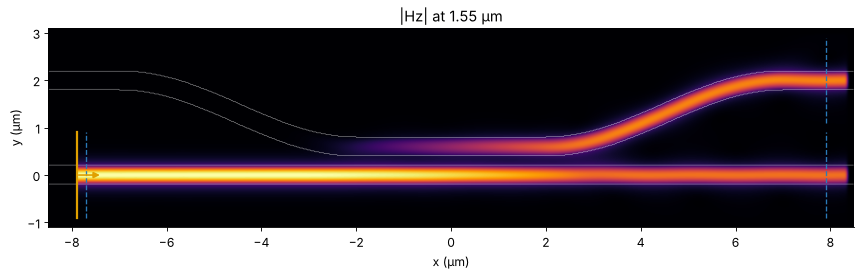

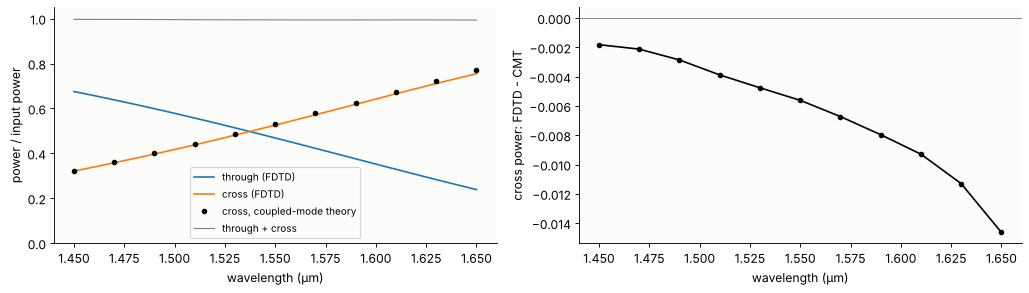

In [7]:
gap, off, Ls, Lstraight = 0.2, 1.4, 5.0, 4.0
d = w + gap


def upper_y(x):
    # centre line of the upper waveguide: in, S-bend down, straight, S-bend up
    x = np.asarray(x, float)
    y = np.full(x.shape, d)
    a = x < -Lstraight/2
    y[a] = d + off*(1 + np.cos(np.pi*np.clip((x[a] + Lstraight/2 + Ls)/Ls, 0, 1)))/2
    b = x > Lstraight/2
    y[b] = d + off*(1 - np.cos(np.pi*np.clip((x[b] - Lstraight/2)/Ls, 0, 1)))/2
    return y


X = 2*(Lstraight/2 + Ls) + 3
xs = np.linspace(-X/2 - 1, X/2 + 1, 1500)
coupler = [(fdtd.Rect((0, 0), (40, w)), CORE), (fdtd.Path(np.stack([xs, upper_y(xs)], 1), w), CORE)]
lower_win, upper_win = (-0.9, 0.9), (d + off - 0.9, d + off + 0.9)
src = fdtd.ModeSource(-X/2 + 0.6, pulse, extent=lower_win)
inc = fdtd.ModeMonitor(-X/2 + 0.8, wls, extent=lower_win, every=8)
thr = fdtd.ModeMonitor(X/2 - 0.6, wls, extent=lower_win, every=8)
crs = fdtd.ModeMonitor(X/2 - 0.6, wls, extent=upper_win, every=8)
dft_c = fdtd.DFTField([WL], components=["Hz"])
csim = fdtd.Simulation(fdtd.Grid((X, 4.2), H, center=(0, 1.0)), coupler, [src],
                       [inc, thr, crs, dft_c], mode="Hz", background=OXIDE)
csim.run(time=150, progress=True)
P0 = inc.power()[0]
T_thr, T_crs = thr.power()[0]/P0, crs.power()[0]/P0

# coupled-mode theory from the supermodes, at a few wavelengths
gx = upper_y(xs) - w
cmt_wls = wls[::8]
g_tab = np.linspace(gap, gap + off + 0.4, 24)
P_cmt = []
for wl in cmt_wls:
    s = [fdtd.section_modes(pair(g), wl, (-2.5, 2.5), H, "Hz", OXIDE, num_modes=2) for g in g_tab]
    kap = np.array([(m[0].beta - m[1].beta)/2 if len(m) > 1 else 0.0 for m in s])
    P_cmt.append(np.sin(np.trapezoid(np.interp(gx, g_tab, kap, right=0), xs))**2)

fig, ax = plt.subplots(figsize=(13, 3.4))
x, y = dft_c.coords("Hz")
ax.imshow(np.abs(dft_c.field("Hz")[0]).T, origin="lower", extent=fplot._extent((x, y)),
          cmap="inferno", aspect="equal")
fplot._structure_outline(ax, csim, color="w", lw=0.5)
fplot._overlays(ax, csim, show_pml=False)
ax.set(title="|Hz| at 1.55 µm", xlabel="x (µm)", ylabel="y (µm)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(wls, T_thr, label="through (FDTD)")
ax[0].plot(wls, T_crs, label="cross (FDTD)")
ax[0].plot(cmt_wls, P_cmt, "ko", ms=4, label="cross, coupled-mode theory")
ax[0].plot(wls, T_thr + T_crs, "0.5", lw=1, label="through + cross")
ax[0].set(xlabel="wavelength (µm)", ylabel="power / input power", ylim=(0, 1.05))
ax[0].legend(fontsize=9)
ax[1].plot(cmt_wls, T_crs[::8] - P_cmt, "ko-", ms=4)
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set(xlabel="wavelength (µm)", ylabel="cross power: FDTD - CMT")
plt.tight_layout()
print("max |FDTD - CMT| of the cross power: %.3f" % np.max(np.abs(T_crs[::8] - P_cmt)))
print("excess loss (S-bends): %.2f %%" % (100*(1 - np.mean(T_thr + T_crs))))

Coupled-mode theory with the supermodes of the mode solver predicts the
FDTD's cross power to about 1 % over the whole band, including the
coupling in the S-bends. The split depends on the wavelength because the
evanescent tails, and with them the coupling, grow with it: this coupler
splits 50:50 near 1.56 µm. The sum of the two outputs is 99.5 %; the rest
radiates from the S-bends.

## 5. Ring resonator

A ring next to a waveguide is a resonator: light that couples into the
ring returns to the coupler after one round trip, and where the round trip
phase is a multiple of $2\pi$,

$$m\,\lambda_m = n_\mathrm{eff}\,2\pi R ,$$

it builds up. With a second waveguide on the other side (an **add-drop**
filter), resonant light leaves through the drop port and is missing from
the through port. Neighbouring resonances are one **free spectral range**
apart, $\mathrm{FSR} = \lambda^2/(n_g\,2\pi R)$, set by the group index
$n_g = n_\mathrm{eff} - \lambda\,dn_\mathrm{eff}/d\lambda$ (with the
dispersion of the waveguide, not just the index). The width of a resonance
is set by the **quality factor** $Q = \lambda/\Delta\lambda$: the number of
optical periods, times $2\pi$, the ring stores its energy for.

The ring here: radius 2.5 µm, 400 nm wide, 150 nm gaps, in water (a
sensor, section 6). Long-lived resonances need long runs: the spectrum
needs a run of a few photon lifetimes $\tau = Q/\omega$. The quality
factors come faster from the decay of the field in the ring after a short
pulse: `fdtd.resonances()` fits a sum of damped sinusoids to the probe
signal with the matrix pencil method (harmonic inversion), which needs
only part of a lifetime.

In [8]:
R_ring, gap_ring, H_ring = 2.5, 0.15, 0.025
yb = R_ring + w + gap_ring


def ring_sim(clad, monitors=(), sources=None, extra=()):
    X, Y = 2*R_ring + 2.6, 2*yb + 1.8
    st = [(fdtd.Rect((0, -yb), (20, w)), CORE), (fdtd.Rect((0, yb), (20, w)), CORE),
          (fdtd.Ring((0, 0), R_ring, w), CORE)]
    probe = fdtd.Probe((R_ring*np.cos(1.0), R_ring*np.sin(1.0)))
    if sources is None:
        sources = [fdtd.PointSource((R_ring*np.cos(2.5), R_ring*np.sin(2.5)), pulse)]
    sim = fdtd.Simulation(fdtd.Grid((X, Y), H_ring), st, sources, [probe] + list(monitors),
                          mode="Hz", background=clad)
    return sim, probe


def ring_resonances(clad, time_=400):
    sim, probe = ring_sim(clad)
    sim.run(time=time_)
    sel = probe.times > pulse.end + 20
    return fdtd.resonances(probe.values[sel], sim.dt, t0=probe.times[sel][0],
                           band=(1.45, 1.65), min_q=100)


res = ring_resonances(WATER)
print(res)

wavelength   Q            amplitude    decay     
1.6113       882.27       0.4608       0.00221   
1.56299      1207         2.864        0.001665  
1.51752      1960.9       0.1806       0.001056  
1.47411      2172.8       2.028        0.0009809 


Four resonances in the band, with Q between 900 and 2200. Now the
add-drop spectrum: a mode source in the lower (input) waveguide, mode
monitors at its end (through) and at the left end of the upper waveguide
(drop: the ring circulates counter-clockwise, so the dropped light travels
towards −x), and field maps at a resonance and between two.

In [9]:
wls_r = np.linspace(1.45, 1.65, 2001)
win_lo, win_up = (-yb - 0.7, -yb + 0.7), (yb - 0.7, yb + 0.7)
X = 2*R_ring + 2.6
lam_on = res.wavelength[np.argmin(np.abs(res.wavelength - 1.56))]
lam_off = lam_on - 0.023
src = fdtd.ModeSource(-X/2 + 0.6, pulse, extent=win_lo)
inc = fdtd.ModeMonitor(-X/2 + 0.8, wls_r, extent=win_lo, every=8)
thr = fdtd.ModeMonitor(X/2 - 0.6, wls_r, extent=win_lo, every=8)
drp = fdtd.ModeMonitor(-X/2 + 0.6, wls_r, extent=win_up, every=8)
dft_r = fdtd.DFTField([lam_on, lam_off], components=["Hz"], stride=2)
rsim, rprobe = ring_sim(WATER, [inc, thr, drp, dft_r], sources=[src])
rsim.run(time=3000, progress=True)
P0 = inc.power()[0]
T_ring, D_ring = thr.power()[0]/P0, drp.power()[1]/P0

# group index of the straight waveguide in water -> predicted FSR
m_a, m_b = [fdtd.section_modes([(fdtd.Rect((0, 0), (1, w)), CORE)], wl, (-1.5, 1.5), H_ring,
                               "Hz", WATER)[0] for wl in (1.55, 1.56)]
n_g = m_a.n_eff - 1.55*(m_b.n_eff - m_a.n_eff)/0.01
print("straight waveguide in water: n_eff = %.4f, n_g = %.3f" % (m_a.n_eff, n_g))
print("FSR at 1.54 µm: predicted %.1f nm, FDTD %.1f nm"
      % (1e3*1.54**2/(n_g*2*np.pi*R_ring), 1e3*np.abs(np.diff(res.wavelength))[1]))

171420 steps in 171.19 s (96.2 Mcell updates/s)
straight waveguide in water: n_eff = 2.2971, n_g = 3.314
FSR at 1.54 µm: predicted 45.6 nm, FDTD 45.5 nm


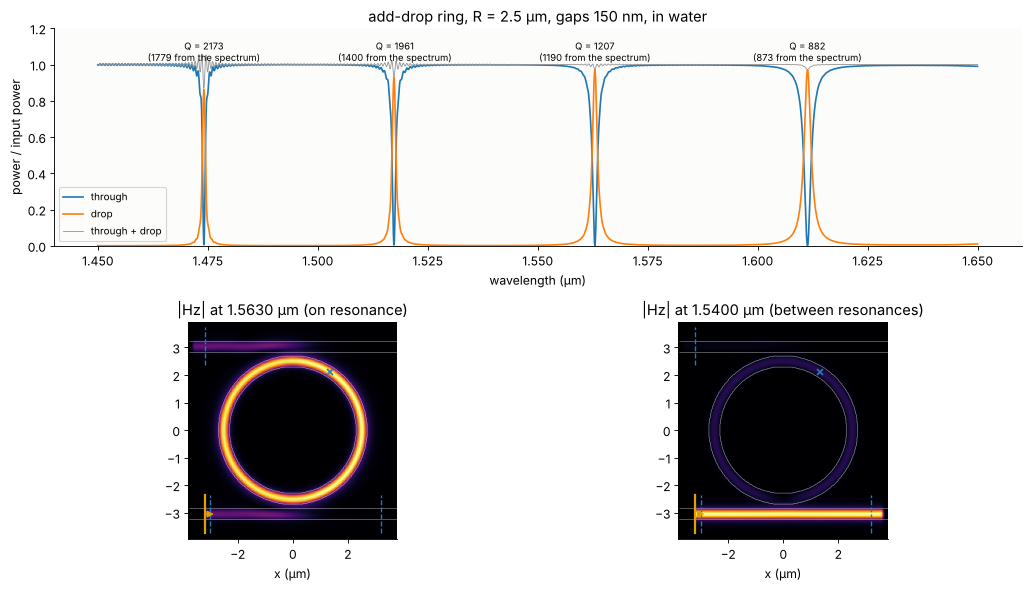

In [10]:
def lorentz_fwhm(wl, D, center):
    # FWHM of the drop peak from the half maximum crossings
    k = np.argmin(np.abs(wl - center))
    half = D[k]/2
    lo = k - np.argmax(D[k::-1] < half)
    hi = k + np.argmax(D[k:] < half)
    f = lambda i0, i1: np.interp(half, [D[i0], D[i1]], [wl[i0], wl[i1]])
    return f(hi, hi - 1) - f(lo, lo + 1), D[k], T_ring[k]


fig = plt.figure(figsize=(13, 7.5))
ax = fig.add_subplot(2, 1, 1)
ax.plot(wls_r, T_ring, label="through")
ax.plot(wls_r, D_ring, label="drop")
ax.plot(wls_r, T_ring + D_ring, color="0.6", lw=0.8, label="through + drop")
for lam, Q in zip(res.wavelength, res.Q):
    fwhm, Dpk, Tmin = lorentz_fwhm(wls_r, D_ring, lam)
    ax.annotate("Q = %.0f\n(%.0f from the spectrum)" % (Q, lam/fwhm), (lam, 1.02), ha="center",
                fontsize=8.5)
ax.set(xlabel="wavelength (µm)", ylabel="power / input power", ylim=(0, 1.2),
       title="add-drop ring, R = 2.5 µm, gaps 150 nm, in water")
ax.legend(fontsize=9, loc="lower left")
x, y = dft_r.coords("Hz")
for k, (lam, name) in enumerate(((lam_on, "on resonance"), (lam_off, "between resonances"))):
    a = fig.add_subplot(2, 2, 3 + k)
    a.imshow(np.abs(dft_r.field("Hz")[k]).T, origin="lower", extent=fplot._extent((x, y)),
             cmap="inferno")
    fplot._structure_outline(a, rsim, color="w", lw=0.5)
    fplot._overlays(a, rsim, show_pml=False)
    a.set(title="|Hz| at %.4f µm (%s)" % (lam, name), xlabel="x (µm)")
plt.tight_layout()

On resonance the light circulates in the ring and leaves through the drop
port; between resonances it passes by. The free spectral range agrees with
the group index of the straight waveguide to about 1 % (the mode of a bent
waveguide is pushed outwards, so its index differs slightly).

For the two low-Q resonances the quality factors from the matrix pencil
(from a run of 400 µm/c) and from the line widths of the spectrum (3000
µm/c) agree to 1 to 2 %. For the high-Q ones the spectrum is too broad,
and it ripples next to them: the field in a resonator decays as
$e^{-\omega t/2Q}$, by 1/e in $2Q/\omega \approx 1000$ µm/c at Q = 2200, so
after 3000 µm/c 5 % of the field is still in the ring, and cutting the
record off broadens the line. The spectrum would need a run several times
longer; the matrix pencil fits the decay itself and needs only a part of
it.

The matrix pencil also resolves what the spectrum cannot. With more poles
and the probe record of the long run, two of the resonances turn out to be
**doublets**:

In [11]:
sel = rprobe.times > 600
fine = fdtd.resonances(rprobe.values[sel], rsim.dt, t0=rprobe.times[sel][0], band=(1.45, 1.65),
                       max_poles=60, min_amplitude=1e-4, min_q=100)
print(fine)

wavelength   Q            amplitude    decay     
1.61141      888.22       0.00918      0.002195  
1.61125      891.26       0.1555       0.002188  
1.563        1216.1       0.001887     0.001653  
1.56299      1204.9       0.1629       0.001668  
1.51735      1624.7       0.1247       0.001274  
1.51731      1624.1       0.04822      0.001275  
1.47411      2172.1       0.08635      0.0009812 


The pairs near 1.517 and 1.611 µm are split by 0.03 to 0.16 nm, less
than their line widths. The staircase of the ring on the grid (and in a
real ring its sidewall roughness) scatters a little light from the
clockwise into the counter-clockwise wave; the two coupled waves form
standing-wave modes with slightly different frequencies. Single-pole fits
of such a pair (as in the 400 µm/c analysis above) average them and
overestimate Q.

Through and drop do not add up to 1 on resonance: in this 2D model the
ring radiates from its bend (section 3), and the light stored in it has
many round trips to do so. The loss limits the intrinsic Q; the coupling
to the two waveguides sets the rest. Q rises towards shorter wavelengths
because the mode is bound more tightly there, which reduces both the
coupling and the radiation.

## 6. Ring resonator sensing

The evanescent field of the ring reaches into the surroundings. If their
refractive index changes, e.g. when molecules bind to the surface or a
solution's concentration changes, $n_\mathrm{eff}$ changes and the
resonances move:

$$\Delta\lambda = \frac{\lambda\,\Delta n_\mathrm{eff}}{n_g} = \frac{\lambda}{n_g}\,\frac{\partial n_\mathrm{eff}}{\partial n_\mathrm{clad}}\,\Delta n_\mathrm{clad}.$$

The bulk sensitivity $S = \Delta\lambda/\Delta n_\mathrm{clad}$ follows from
the mode solver with two cladding indices. The FDTD measures the shift of
the resonances directly with two more short runs and the matrix pencil
(whose precision is far below the line width):

at 1.563 µm: S = 144 nm/RIU, line width 1.29 nm, figure of merit S/FWHM = 111 /RIU
total run time of the notebook: 261 s


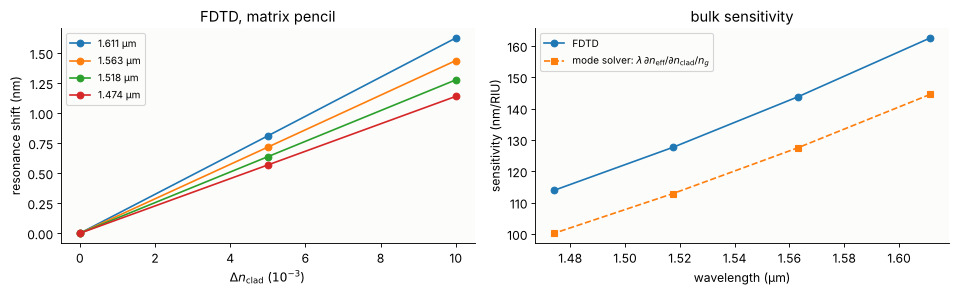

In [12]:
dn_clad = [0.0, 0.005, 0.01]
shifts = []
for dn in dn_clad:
    r = res if dn == 0 else ring_resonances(fdtd.Medium.from_index(1.33 + dn))
    shifts.append(r.wavelength)
shifts = np.array(shifts)
S_fdtd = np.polyfit(dn_clad, shifts, 1)[0]        # µm per RIU, per resonance

S_pred = []
for lam in res.wavelength:
    ms = [fdtd.section_modes([(fdtd.Rect((0, 0), (1, w)), CORE)], wl, (-1.5, 1.5), H_ring, "Hz",
                             fdtd.Medium.from_index(nc))[0]
          for wl, nc in ((lam, 1.33), (lam, 1.34), (lam + 0.01, 1.33))]
    dneff = (ms[1].n_eff - ms[0].n_eff)/0.01
    ng = ms[0].n_eff - lam*(ms[2].n_eff - ms[0].n_eff)/0.01
    S_pred.append(lam*dneff/ng)
S_pred = np.array(S_pred)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, lam in enumerate(res.wavelength):
    ax[0].plot(np.array(dn_clad)*1e3, (shifts[:, k] - shifts[0, k])*1e3, "o-",
               label="%.3f µm" % lam)
ax[0].set(xlabel=r"$\Delta n_\mathrm{clad}$ ($10^{-3}$)", ylabel="resonance shift (nm)",
          title="FDTD, matrix pencil")
ax[0].legend(fontsize=9)
ax[1].plot(res.wavelength, S_fdtd*1e3, "o-", label="FDTD")
ax[1].plot(res.wavelength, S_pred*1e3, "s--", label=r"mode solver: $\lambda\,\partial n_\mathrm{eff}/\partial n_\mathrm{clad}/n_g$")
ax[1].set(xlabel="wavelength (µm)", ylabel="sensitivity (nm/RIU)", title="bulk sensitivity")
ax[1].legend(fontsize=9)
plt.tight_layout()
k = np.argmin(np.abs(res.wavelength - 1.56))
fwhm = res.wavelength[k]/res.Q[k]
print("at %.3f µm: S = %.0f nm/RIU, line width %.2f nm, figure of merit S/FWHM = %.0f /RIU"
      % (res.wavelength[k], S_fdtd[k]*1e3, fwhm*1e3, S_fdtd[k]/fwhm))
print("total run time of the notebook: %.0f s" % (time.perf_counter() - t_start))

The FDTD sensitivity is 10 to 14 % above the estimate from the straight
waveguide: in the bend the mode moves towards the outer wall, and more of
its field lies in the water. The shift is linear in the index change, and longer wavelengths
are more sensitive because their evanescent fields reach further out.

What matters for detection is the shift relative to the line width, the
figure of merit $S/\Delta\lambda$: a resonance can be located to a small
fraction of its width, so changes of $10^{-5}$ to $10^{-6}$ RIU are
detectable with rings like this one, and real silicon rings with Q of
$10^4$ to $10^5$ go further. The same trade-off as for surface plasmon
sensors (notebook [59](59_fdtd_metals_plasmons.ipynb)) applies: a field
that reaches further into the sample shifts more, but it is often also
less confined and lossier.

## Summary

- `fdtd.waveguide_modes`, `find_modes` and `section_modes` solve waveguide
  cross sections, exactly on the Yee grid of a simulation; the slab modes
  converge to the analytic ones with the square of the cell size.
- `fdtd.ModeSource` launches one mode in one direction (backward leakage
  1e-5 to 1e-4 away from the centre wavelength, none at it);
  `fdtd.ModeMonitor` splits the fields into forward and backward mode
  amplitudes, whose ratios are S-parameters.
- Bends, directional couplers and rings are drawn with `fdtd.Bend`,
  `fdtd.Path`, `fdtd.SBend` and `fdtd.Ring`; coupled-mode theory with
  supermodes from the solver predicts the coupler to about 1 %.
- `fdtd.resonances` extracts frequencies and Q from short ring-down
  signals; resonance shifts give sensor sensitivities in a few seconds of
  simulation each.

The 2D model with an effective index captures the physics in the plane of
the chip; the out-of-plane confinement (and substrate leakage) needs 3D,
planned in proposals/fdtd.md together with Bloch boundaries for photonic
crystals.